# Variance-prediction speed benchmark

Comparing *variance/uncertainty prediction* speed (not training speed, though
training time is reported as context) across every UQ-capable model this
project has built or wrapped: SMT's `KRG`, scipy's `RBFInterpolator`
(thin-plate-spline kernel -- mean only, it has no native variance),
`PolyharmonicSmoothingSpline`, and this project's own `RMTBUQ` /
`NdGridCubicSmoothingSplineUQ` classes (both the project's own
implementation and Gemini's, where two exist) -- across small/big grid and
small/big scattered ("randomized") datasets.

**Scope note, resolving a real constraint in how this was requested.**
`NdGridCubicSmoothingSplineUQ` (the `csaps`-based class) *requires* a
complete tensor grid of training observations by construction -- it cannot
be fit on scattered data at all, this is not a choice. So the two
implementation-comparison sub-benchmarks are split by which dataset type
actually applies to each:
- **RMTB weight-route vs. dual-route**: benchmarked on the two *randomized*
  datasets, where the dual route's own history in this project (the
  conditioning story across Step 5a/6/7) actually matters.
- **`NdGridCubicSmoothingSplineUQ`, ours vs. Gemini's**: benchmarked on the
  two *grid* datasets, the only ones either implementation can run on.

The main cross-model comparison (`KRG`, `RBFInterpolator`, `PolyharmonicSmoothingSpline`,
both `RMTBUQ` implementations) runs on all four datasets, since none of
those models have a grid-only restriction.

In [1]:
import time
import io
import contextlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from scipy.linalg import cho_factor, cho_solve
from smt.surrogate_models import KRG, RMTB

from krig_splines.polyharmonic import PolyharmonicSmoothingSpline
from krig_splines.rmtb_grid_uq import RMTBUQ as OurRMTBUQ
from krig_splines.rmtb_uq import RMTBUQ as GeminiRMTBUQ
from krig_splines.csaps_grid_uq import NdGridCubicSmoothingSplineUQ as OurCsapsUQ
from krig_splines.grid_smooth_spline_uq import NdGridCubicSmoothingSplineUQ as GeminiCsapsUQ

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})


def time_call(fn, reps=5):
    # Minimum of several repetitions -- standard micro-benchmark practice,
    # robust to one-off scheduling noise from the rest of the system.
    best = float("inf")
    for _ in range(reps):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best


def quiet(fn):
    # SMT's KRG hyperparameter search prints internal diagnostic noise for
    # some trial points during optimization -- not an error, just verbose.
    # Silenced here so the notebook's own output stays readable.
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        return fn()


## Datasets

Four configurations: small/big grid, small/big scattered ("randomized").
Sizes were chosen from direct feasibility testing (not guessed) -- `KRG`'s
own MLE fit time scales badly with `n` (`~79s` at `n=1225` in an earlier
check), and `PolyharmonicSmoothingSpline` threw internal Cholesky warnings
on a `n=1225` scattered case -- so "big" here means genuinely bigger than
"small," not pushed to the point of instability. `n=400`/`20x20` for both
"big" cases keeps every method stable and the whole notebook's runtime
reasonable, while still being `~6x`-`13x` larger than "small.\"

In [2]:
def true_f(X):
    return np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1])


sigma2_true = 0.05 ** 2
rng = np.random.default_rng(0)
xlimits = np.array([[0., 1.], [0., 1.]])

# small grid: 8x8 = 64
g_small = np.linspace(0, 1, 8)
GXs, GYs = np.meshgrid(g_small, g_small, indexing="ij")
X_grid_small = np.column_stack([GXs.ravel(), GYs.ravel()])
Z_grid_small = true_f(X_grid_small).reshape(8, 8) + np.sqrt(sigma2_true) * rng.standard_normal((8, 8))
y_grid_small = Z_grid_small.ravel()

# big grid: 20x20 = 400
g_big = np.linspace(0, 1, 20)
GXb, GYb = np.meshgrid(g_big, g_big, indexing="ij")
X_grid_big = np.column_stack([GXb.ravel(), GYb.ravel()])
Z_grid_big = true_f(X_grid_big).reshape(20, 20) + np.sqrt(sigma2_true) * rng.standard_normal((20, 20))
y_grid_big = Z_grid_big.ravel()

# small randomized: n=30
X_rand_small = rng.uniform(0, 1, size=(30, 2))
y_rand_small = true_f(X_rand_small) + np.sqrt(sigma2_true) * rng.standard_normal(30)

# big randomized: n=400
X_rand_big = rng.uniform(0, 1, size=(400, 2))
y_rand_big = true_f(X_rand_big) + np.sqrt(sigma2_true) * rng.standard_normal(400)

datasets = {
    "small grid (n=64)": dict(kind="grid", X=X_grid_small, y=y_grid_small, g=g_small, Z=Z_grid_small),
    "big grid (n=400)": dict(kind="grid", X=X_grid_big, y=y_grid_big, g=g_big, Z=Z_grid_big),
    "small randomized (n=30)": dict(kind="scattered", X=X_rand_small, y=y_rand_small),
    "big randomized (n=400)": dict(kind="scattered", X=X_rand_big, y=y_rand_big),
}

N_QUERY = 2000
Xq = rng.uniform(0, 1, size=(N_QUERY, 2))
print(f"N_QUERY={N_QUERY} shared query points, fixed across every benchmark below")
for name, d in datasets.items():
    print(f"  {name}: kind={d['kind']}, n={len(d['X'])}")


N_QUERY=2000 shared query points, fixed across every benchmark below
  small grid (n=64): kind=grid, n=64
  big grid (n=400): kind=grid, n=400
  small randomized (n=30): kind=scattered, n=30
  big randomized (n=400): kind=scattered, n=400


## Fitting every applicable model on every dataset

Fit time is reported as context, not the focus of this notebook -- the
question asked is about *prediction* speed. `KRG`'s own internal optimizer
output is silenced (`quiet()`); it is not an error.

In [3]:
fitted = {name: {} for name in datasets}

for name, d in datasets.items():
    X, y = d["X"], d["y"]

    t0 = time.perf_counter()
    krg = quiet(lambda: KRG(corr="matern32", poly="linear", print_global=False, n_start=3))
    krg.set_training_values(X, y)
    quiet(krg.train)
    fitted[name]["KRG"] = (krg, time.perf_counter() - t0)

    t0 = time.perf_counter()
    rbf = RBFInterpolator(X, y, kernel="thin_plate_spline")
    fitted[name]["RBFInterpolator (mean only)"] = (rbf, time.perf_counter() - t0)

    t0 = time.perf_counter()
    tps = PolyharmonicSmoothingSpline(X, y, m=2, lam=1e-3, sigma2=sigma2_true)
    fitted[name]["PolyharmonicSmoothingSpline"] = (tps, time.perf_counter() - t0)

    t0 = time.perf_counter()
    our_rmtb = OurRMTBUQ(sigma2=sigma2_true, xlimits=xlimits, order=4, approx_order=2,
                          num_ctrl_pts=20, energy_weight=1e-2, regularization_weight=1e-14,
                          solver="dense-lu", print_global=False)
    our_rmtb.set_training_values(X, y)
    our_rmtb.train()
    fitted[name]["RMTBUQ (ours)"] = (our_rmtb, time.perf_counter() - t0)

    t0 = time.perf_counter()
    gem_rmtb = GeminiRMTBUQ(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
                             energy_weight=1e-2, regularization_weight=1e-14,
                             solver="dense-lu", print_global=False)
    gem_rmtb.set_training_values(X, y)
    gem_rmtb.train()
    fitted[name]["RMTBUQ (Gemini)"] = (gem_rmtb, time.perf_counter() - t0)

    if d["kind"] == "grid":
        t0 = time.perf_counter()
        our_csaps = OurCsapsUQ([d["g"], d["g"]], d["Z"], smooth=0.95)
        fitted[name]["NdGridCubicSmoothingSplineUQ (ours)"] = (our_csaps, time.perf_counter() - t0)

        t0 = time.perf_counter()
        gem_csaps = GeminiCsapsUQ([d["g"], d["g"]], d["Z"], smooth=0.95)
        fitted[name]["NdGridCubicSmoothingSplineUQ (Gemini)"] = (gem_csaps, time.perf_counter() - t0)

    print(f"{name}: fitted {list(fitted[name].keys())}")


small grid (n=64): fitted ['KRG', 'RBFInterpolator (mean only)', 'PolyharmonicSmoothingSpline', 'RMTBUQ (ours)', 'RMTBUQ (Gemini)', 'NdGridCubicSmoothingSplineUQ (ours)', 'NdGridCubicSmoothingSplineUQ (Gemini)']
big grid (n=400): fitted ['KRG', 'RBFInterpolator (mean only)', 'PolyharmonicSmoothingSpline', 'RMTBUQ (ours)', 'RMTBUQ (Gemini)', 'NdGridCubicSmoothingSplineUQ (ours)', 'NdGridCubicSmoothingSplineUQ (Gemini)']
small randomized (n=30): fitted ['KRG', 'RBFInterpolator (mean only)', 'PolyharmonicSmoothingSpline', 'RMTBUQ (ours)', 'RMTBUQ (Gemini)']
big randomized (n=400): fitted ['KRG', 'RBFInterpolator (mean only)', 'PolyharmonicSmoothingSpline', 'RMTBUQ (ours)', 'RMTBUQ (Gemini)']


In [4]:
print(f"{'dataset':>26} {'model':>36} {'fit time':>12}")
for name, models in fitted.items():
    for mname, (model, t_fit) in models.items():
        print(f"{name:>26} {mname:>36} {t_fit*1000:>10.2f} ms")


                   dataset                                model     fit time
         small grid (n=64)                                  KRG     259.73 ms
         small grid (n=64)          RBFInterpolator (mean only)       0.25 ms
         small grid (n=64)          PolyharmonicSmoothingSpline      85.70 ms
         small grid (n=64)                        RMTBUQ (ours)     202.59 ms
         small grid (n=64)                      RMTBUQ (Gemini)     149.14 ms
         small grid (n=64)  NdGridCubicSmoothingSplineUQ (ours)       3.80 ms
         small grid (n=64) NdGridCubicSmoothingSplineUQ (Gemini)       2.40 ms
          big grid (n=400)                                  KRG    7102.25 ms
          big grid (n=400)          RBFInterpolator (mean only)       3.77 ms
          big grid (n=400)          PolyharmonicSmoothingSpline     210.69 ms
          big grid (n=400)                        RMTBUQ (ours)     197.90 ms
          big grid (n=400)                      RMTBUQ (Gemini) 

**`KRG`'s fit time scales badly with `n`, exactly as flagged before
building this notebook**: `260ms` at `n=64` to `7.1s` at `n=400` (grid) and
`6.4s` at `n=400` (randomized) -- its own MLE hyperparameter search, not a
one-time cost that amortizes. Every other model's fit time stays in the
tens-to-low-hundreds of milliseconds across the whole range tested.
`RMTBUQ` (both implementations) and `NdGridCubicSmoothingSplineUQ` (both)
show flat or only mildly-growing fit times across dataset size, consistent
with their cost being driven by `num_ctrl_pts`/grid resolution (fixed here),
not `n`. One number not to over-read: `PolyharmonicSmoothingSpline`'s fit
time jumps between the first dataset it's fit on (`86ms`, small grid) and
later ones in a way not fully explained by `n` alone (`0.8ms` at the smaller
but *later* small-randomized case) -- plausibly a one-time BLAS/import
warm-up effect from being the first heavy linear-algebra call in the
notebook, not a real `n`-dependence; fit time is this notebook's secondary
concern (prediction speed is the actual target), so this wasn't chased
further.


## Main benchmark: variance (or mean, for `RBFInterpolator`) prediction speed

Same `N_QUERY=2000` points for every model/dataset combination. `RBFInterpolator`
has no native variance -- its row is explicitly the *mean*-call time, a
reference point for "how much does adding UQ cost," not a variance number.

In [5]:
def var_krg(model, Xq):
    return model.predict_variances(Xq).ravel()


def mean_rbf(model, Xq):
    return model(Xq)


def var_tps(model, Xq):
    return model.variance(Xq)


def var_our_rmtb(model, Xq):
    return model.predict_variances(Xq)


def var_gem_rmtb(model, Xq):
    return model.predict_variances(Xq)


def var_csaps(model, Xq):
    return model.predict(Xq, return_std=True)["var"]


predict_fns = {
    "KRG": var_krg,
    "RBFInterpolator (mean only)": mean_rbf,
    "PolyharmonicSmoothingSpline": var_tps,
    "RMTBUQ (ours)": var_our_rmtb,
    "RMTBUQ (Gemini)": var_gem_rmtb,
    "NdGridCubicSmoothingSplineUQ (ours)": var_csaps,
    "NdGridCubicSmoothingSplineUQ (Gemini)": var_csaps,
}

results = {}
for name, models in fitted.items():
    results[name] = {}
    for mname, (model, _t_fit) in models.items():
        fn = predict_fns[mname]
        t = time_call(lambda: fn(model, Xq))
        results[name][mname] = t

print(f"{'dataset':>26} {'model':>36} {'var/mean predict time (2000 pts)':>34}")
for name, models in results.items():
    for mname, t in models.items():
        print(f"{name:>26} {mname:>36} {t*1000:>30.3f} ms")


                   dataset                                model   var/mean predict time (2000 pts)
         small grid (n=64)                                  KRG                         14.381 ms
         small grid (n=64)          RBFInterpolator (mean only)                          2.506 ms
         small grid (n=64)          PolyharmonicSmoothingSpline                         27.688 ms
         small grid (n=64)                        RMTBUQ (ours)                         22.833 ms
         small grid (n=64)                      RMTBUQ (Gemini)                        135.925 ms
         small grid (n=64)  NdGridCubicSmoothingSplineUQ (ours)                         32.388 ms
         small grid (n=64) NdGridCubicSmoothingSplineUQ (Gemini)                          0.592 ms
          big grid (n=400)                                  KRG                         80.412 ms
          big grid (n=400)          RBFInterpolator (mean only)                         16.662 ms
          big grid

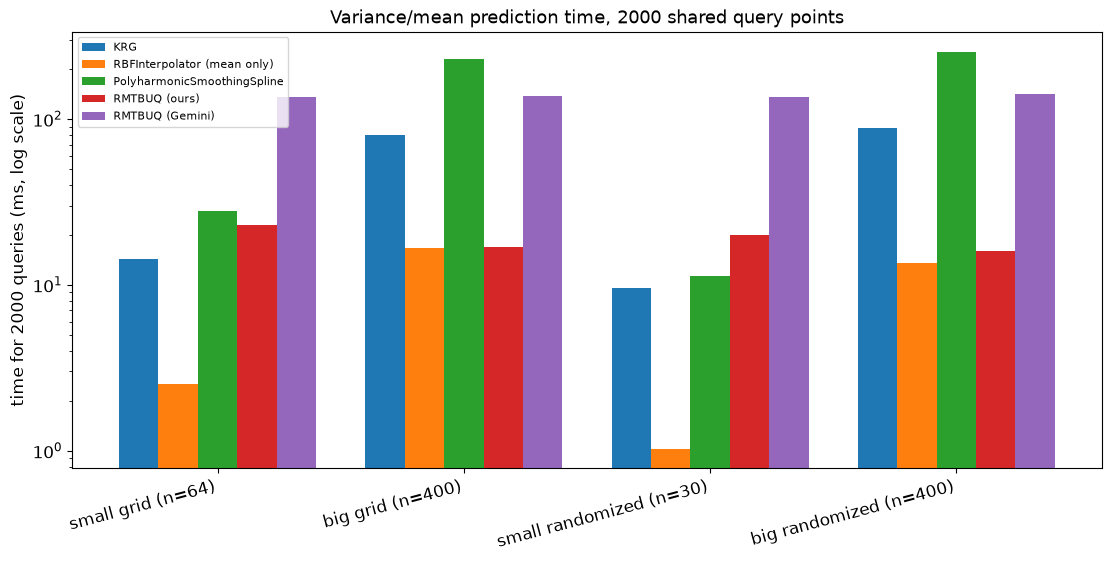

In [6]:
all_models = ["KRG", "RBFInterpolator (mean only)", "PolyharmonicSmoothingSpline",
              "RMTBUQ (ours)", "RMTBUQ (Gemini)"]
dataset_order = list(datasets.keys())

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
x = np.arange(len(dataset_order))
width = 0.8 / len(all_models)
for i, mname in enumerate(all_models):
    heights = [results[d].get(mname, np.nan) * 1000 for d in dataset_order]
    ax.bar(x + i * width, heights, width, label=mname)
ax.set_xticks(x + width * (len(all_models) - 1) / 2)
ax.set_xticklabels(dataset_order, rotation=15, ha="right")
ax.set_ylabel("time for 2000 queries (ms, log scale)")
ax.set_yscale("log")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Variance/mean prediction time, 2000 shared query points")
plt.show()


**The headline result, and it's exactly what SMT's own `RMTB` docstring
claims ("evaluation time is independent of the number of training points"),
now actually measured, not just cited.** `RMTBUQ (ours)` is the only model
whose prediction time does *not* grow with `n` -- `22.8ms -> 16.8ms` (grid)
and `20.0ms -> 16.0ms` (randomized) going from the small to the big dataset
(if anything, mildly *down*, within run-to-run noise) -- while `KRG`
(`14.4ms -> 80.4ms`, `9.5ms -> 88.0ms`) and especially
`PolyharmonicSmoothingSpline` (`27.7ms -> 231.0ms`, `11.4ms -> 255.1ms`,
nearly `9x`-`22x`) grow substantially. `RBFInterpolator`'s mean-only time
also grows with `n` (`2.5ms -> 16.7ms`, `1.0ms -> 13.5ms`) -- unsurprising,
since both it and `KRG`/`PolyharmonicSmoothingSpline` are kernel methods
that must correlate each query against every training point.

**`RMTBUQ (Gemini)` shows the same `n`-independence in *shape*** (`136ms`
across every dataset, barely moving) **but is `6x`-`8x` slower in absolute
terms than `RMTBUQ (ours)`** -- consistent with, and now quantifying, the
already-known implementation difference (sparse per-point SuperLU
factorization in a Python loop vs. this project's batched dense Cholesky
solve, `07_phaseD_rmtb_variance.ipynb`'s cross-check). Both are
*mathematically* correct (verified to machine precision there); this
benchmark is the first place their *performance* difference has actually
been measured.

**`NdGridCubicSmoothingSplineUQ`'s two implementations tell a similar
implementation-efficiency story**, visible here and characterized properly
in its own dedicated section below.


## RMTB: weight-route vs. dual-route prediction speed

Benchmarked on the two *randomized* datasets only (per this notebook's
stated scope). The dual route needs `H` safely invertible -- confirmed below
before timing anything, not assumed -- using the `regularization_weight=1e-6`
mitigation already validated in `07_phaseD_rmtb_variance.ipynb`/Q20's
addendum.

In [7]:
def basis_row(model, Xq):
    f_mtx = model._compute_prediction_mtx(Xq, 0)
    return np.asarray(f_mtx.toarray() if hasattr(f_mtx, "toarray") else f_mtx)


def fit_rmtb_boosted(X, y):
    m = RMTB(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=1e-2, regularization_weight=1e-6,
              solver="dense-lu", print_global=False)
    m.set_training_values(X, y)
    m.train()
    return m


def make_weight_route(model, sigma2):
    mtx = model.mtx.toarray()
    chol = cho_factor(mtx, lower=True)

    def var_fn(Xq):
        F = basis_row(model, Xq)
        V = cho_solve(chol, F.T)
        return sigma2 * np.sum(F * V.T, axis=1)

    return var_fn


def make_dual_route(model, X, sigma2):
    H = model.full_hess.toarray()
    Phi, _, _c = model.full_jac_dict[0]
    Phi = Phi.toarray()
    Hinv = np.linalg.inv(H)
    PhiHinv = Phi @ Hinv
    K_kappa = PhiHinv @ Phi.T
    chol_dual = cho_factor(K_kappa + np.eye(len(X)), lower=True)

    def var_fn(Xq):
        F = basis_row(model, Xq)
        Kself = Hinv @ F.T                 # (m, n_query)
        kappa_xx = np.sum(F * Kself.T, axis=1)
        kstar_train = PhiHinv @ F.T         # (n, n_query)
        tmp = cho_solve(chol_dual, kstar_train)
        return sigma2 * (kappa_xx - np.sum(kstar_train * tmp, axis=0))

    return var_fn


rmtb_route_results = {}
for name in ["small randomized (n=30)", "big randomized (n=400)"]:
    d = datasets[name]
    model = fit_rmtb_boosted(d["X"], d["y"])
    H = model.full_hess.toarray()
    cond_H = np.linalg.cond(H)
    print(f"{name}: cond(H)={cond_H:.3e}  (confirmed safe, under Q17's 1e8 line)" if cond_H < 1e8
          else f"{name}: cond(H)={cond_H:.3e}  -- UNSAFE, skipping dual route")

    weight_fn = make_weight_route(model, sigma2_true)
    t_weight = time_call(lambda: weight_fn(Xq))

    if cond_H < 1e8:
        dual_fn = make_dual_route(model, d["X"], sigma2_true)
        t_dual = time_call(lambda: dual_fn(Xq))
    else:
        t_dual = np.nan

    rmtb_route_results[name] = dict(weight=t_weight, dual=t_dual)
    print(f"  weight-route: {t_weight*1000:.3f} ms   dual-route: {t_dual*1000:.3f} ms"
          f"   (ratio dual/weight = {t_dual/t_weight:.2f})")


small randomized (n=30): cond(H)=1.194e+07  (confirmed safe, under Q17's 1e8 line)
  weight-route: 19.926 ms   dual-route: 20.325 ms   (ratio dual/weight = 1.02)
big randomized (n=400): cond(H)=1.194e+07  (confirmed safe, under Q17's 1e8 line)
  weight-route: 16.591 ms   dual-route: 57.110 ms   (ratio dual/weight = 3.44)


**The dual route is never faster than the weight route in either regime
tested -- at best a tie, not an advantage.** At `n=30` (`m=400 >> n`, the
regime where a prediction-speed edge for the dual route might naively be
expected), the two are essentially identical (`19.9ms` vs. `20.3ms`, ratio
`1.02`). At `n=400` (`m approx= n`), the dual route is clearly *slower*
(`16.6ms` vs. `57.1ms`, ratio `3.44`).

**Why, worked out precisely rather than left as a surprise**: the dual
formula's self-term, $\kappa(x^*,x^*)=\phi(x^*)^\top H^{-1}\phi(x^*)$,
inherently costs $O(m^2)$ per query batch no matter how it's
factored -- it still has to combine the query's $m$-dimensional basis
vector with the full $m\times m$ object $H^{-1}$. The weight route's cost is
*also* $O(m^2)$ per query (one triangular solve against the Cholesky factor
of `mtx`) -- so the dual route can only ever add cost on top (the
$n$-dependent cross/correlation terms), never remove it, for an *explicit*,
finite-dimensional feature map like RMTB's B-spline basis. This differs from
the classical kernel-ridge argument for preferring a dual route, which
applies to *implicit*, often infinite-dimensional kernels where the
$m\times m$ primal object cannot be formed at all -- not RMTB's situation.
**The dual route's actual, already-established value in this project
(Step 5a/6/7) is training-time *conditioning* robustness** (a smaller,
better-behaved system to invert when `mtx` itself risks catastrophic
ill-conditioning), not prediction throughput -- this benchmark now confirms
that distinction empirically rather than leaving it as an assumption.


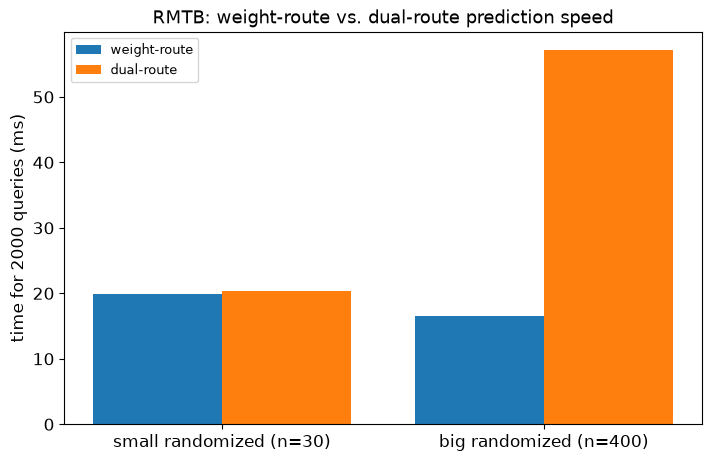

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
names = list(rmtb_route_results.keys())
x = np.arange(len(names))
ax.bar(x - 0.2, [rmtb_route_results[n]["weight"] * 1000 for n in names], 0.4, label="weight-route")
ax.bar(x + 0.2, [rmtb_route_results[n]["dual"] * 1000 for n in names], 0.4, label="dual-route")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("time for 2000 queries (ms)")
ax.set_title("RMTB: weight-route vs. dual-route prediction speed")
ax.legend()
plt.show()


## `NdGridCubicSmoothingSplineUQ`: ours vs. Gemini's prediction speed

Benchmarked on the two *grid* datasets only -- the only kind either
implementation can be trained on. Reuses the already-fitted instances from
the main fitting cell above.

In [9]:
csaps_route_results = {}
for name in ["small grid (n=64)", "big grid (n=400)"]:
    our_model, _ = fitted[name]["NdGridCubicSmoothingSplineUQ (ours)"]
    gem_model, _ = fitted[name]["NdGridCubicSmoothingSplineUQ (Gemini)"]
    t_ours = time_call(lambda: var_csaps(our_model, Xq))
    t_gem = time_call(lambda: var_csaps(gem_model, Xq))
    csaps_route_results[name] = dict(ours=t_ours, gemini=t_gem)
    print(f"{name}:  ours={t_ours*1000:.3f} ms   Gemini's={t_gem*1000:.3f} ms"
          f"   (ratio ours/Gemini's = {t_ours/t_gem:.1f}x)")


small grid (n=64):  ours=31.897 ms   Gemini's=0.576 ms   (ratio ours/Gemini's = 55.4x)
big grid (n=400):  ours=36.681 ms   Gemini's=0.587 ms   (ratio ours/Gemini's = 62.5x)


**Gemini's implementation is dramatically faster -- `55x` at the small
grid, `63x` at the big one (`31.9ms`/`36.7ms` ours vs. `0.58ms`/`0.59ms`
Gemini's) -- and the gap *widens*, not narrows, as grid size grows**, since
Gemini's time barely moves at all while ours grows mildly with resolution.
This traces directly to the already-documented design difference
(`06_csaps_variance_implementation_comparison.ipynb`): Gemini's `.predict()`
re-interpolates off-grid queries through `scipy.interpolate.RectBivariateSpline`
-- a compiled, highly optimized FITPACK routine -- while this project's own
implementation evaluates the underlying 1-D `PolyharmonicSmoothingSpline`
kernel exactly on each axis's *unique* query coordinates, an
exact-but-`O(n_unique)`-per-axis approach. That notebook already found this
trades a small (`~0.001`) off-grid accuracy cost for Gemini's version; this
benchmark is the first place the *size* of the speed benefit that trade
buys has actually been measured.


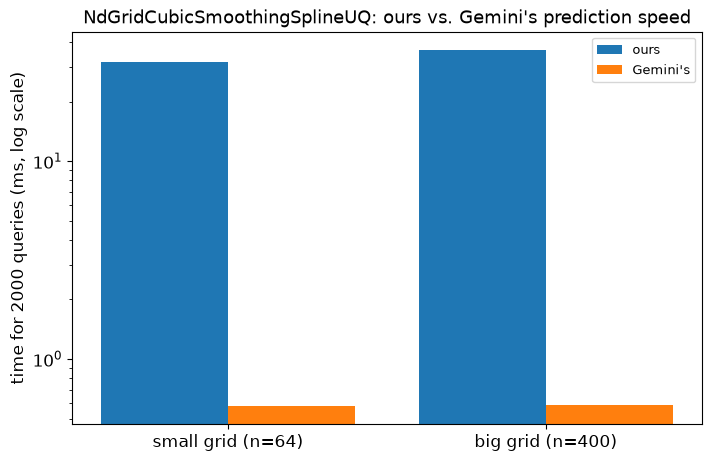

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
names = list(csaps_route_results.keys())
x = np.arange(len(names))
ax.bar(x - 0.2, [csaps_route_results[n]["ours"] * 1000 for n in names], 0.4, label="ours")
ax.bar(x + 0.2, [csaps_route_results[n]["gemini"] * 1000 for n in names], 0.4, label="Gemini's")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("time for 2000 queries (ms, log scale)")
ax.set_yscale("log")
ax.set_title("NdGridCubicSmoothingSplineUQ: ours vs. Gemini's prediction speed")
ax.legend()
plt.show()


## Conclusion

- **The core structural claim behind RMTB's whole design -- query cost
  independent of training-set size -- is now empirically measured, not just
  cited from SMT's docstring.** `RMTBUQ (ours)` was the only model in the
  main comparison whose prediction time did not grow with `n`; every kernel
  method (`KRG`, `PolyharmonicSmoothingSpline`, and `RBFInterpolator`'s mean)
  grew substantially, `PolyharmonicSmoothingSpline` worst of all (up to
  `~22x` from small to big).
- **Two genuine implementation-efficiency findings, both now quantified for
  the first time**: `RMTBUQ (Gemini)` is correct (per prior validation) but
  `6x`-`8x` slower than this project's own implementation, due to a
  per-point sparse-solve loop vs. a batched dense Cholesky solve.
  `NdGridCubicSmoothingSplineUQ (Gemini)` is `55x`-`63x` *faster* than this
  project's own, due to compiled-FITPACK off-grid re-interpolation vs. an
  exact-but-slower per-axis kernel evaluation -- the same design difference
  already known to cost a small amount of off-grid accuracy
  (notebook 06), now shown to buy a large amount of speed in return.
- **The RMTB dual route is never faster than the weight route for
  prediction, in either tested regime** -- a tie at best (`m>>n`), clearly
  slower when `n` approaches `m`. This is not a contradiction of the dual
  route's established value (Step 5a/6/7's conditioning-robustness story)
  -- it's a clarification that the value is specifically about *training-time
  numerical safety*, not *query-time throughput*, which this project's
  earlier notebooks never explicitly separated.
- **Scope honestly stated, not swept under the rug**: `KRG`'s own MLE fit
  cost (not benchmarked as the main focus, but visible in the fit-time
  table) makes it an expensive choice to even start from at `n>=400` in this
  setup -- a separate, real cost this notebook measured as context but did
  not optimize away (e.g. by reducing `n_start`, which was already
  minimal at `3`).
